# Etapa 2 · Modelado con validación segura

**Proyecto integrador — Heart Failure Prediction (MLOps local)**

Este cuaderno toma el modelo ganador de la Etapa 1 y:

1. Hace la **partición de los datos antes de cualquier escalado** o transformación.
2. Ajusta un `Pipeline` (preprocesamiento + clasificador) optimizado con `GridSearchCV` y `StratifiedKFold`.
3. Lo evalúa con **matriz de confusión, curva ROC y AUC**, más las métricas de clasificación.
4. Verifica empíricamente la ausencia de sobreajuste (las cuatro pruebas de la sección 10.18 del curso).
5. Exporta el modelo (`app/model.joblib`) que usa la API de la Etapa 3.
6. Genera el reporte de deriva de datos con Evidently (Etapa 6).

In [1]:
import json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report, roc_curve)
from sklearn.model_selection import cross_validate, learning_curve, permutation_test_score
from sklearn.inspection import permutation_importance


warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

In [2]:
# Funciones reutilizables (las mismas definidas en la Etapa 1)
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

RANDOM_STATE = 42
TARGET = "HeartDisease"

# En este dataset un 0 en colesterol o presión en reposo no es fisiológicamente
# posible: es un valor faltante codificado como 0. Se imputa dentro del pipeline.
ZERO_AS_MISSING_COLS = ["RestingBP", "Cholesterol"]
NUMERIC_COLS = ["Age", "MaxHR", "Oldpeak"]
CATEGORICAL_COLS = ["Sex", "ChestPainType", "FastingBS", "RestingECG",
                    "ExerciseAngina", "ST_Slope"]
FEATURES = ["Age", "Sex", "ChestPainType", "RestingBP", "Cholesterol", "FastingBS",
            "RestingECG", "MaxHR", "ExerciseAngina", "Oldpeak", "ST_Slope"]


def load_data(path) -> pd.DataFrame:
    """Carga el CSV de Kaggle (fedesoriano) y valida sus columnas."""
    if not Path(path).exists():
        raise FileNotFoundError(
            "No se encontró heart.csv. Descárgalo de Kaggle (Heart Failure Prediction) "
            "y colócalo en la carpeta notebooks/."
        )
    df = pd.read_csv(path)
    missing = set(FEATURES + [TARGET]) - set(df.columns)
    if missing:
        raise ValueError(f"Faltan columnas en el dataset: {missing}")
    return df


def split_data(df: pd.DataFrame, test_size: float = 0.2,
               random_state: int = RANDOM_STATE):
    """Separa X/y y hace la partición estratificada ANTES de cualquier ajuste."""
    X = df[FEATURES].copy()
    y = df[TARGET].copy()
    return train_test_split(X, y, test_size=test_size,
                            random_state=random_state, stratify=y)


def build_preprocessor(scaler=None, scale_numeric: bool = True) -> ColumnTransformer:
    """Construye el preprocesamiento sin aprender información fuera del pipeline.

    Los modelos basados en distancias o coeficientes usan escalado. Los árboles
    reciben las variables numéricas sin escalar porque no lo necesitan.
    """
    scaler = scaler if scaler is not None else MinMaxScaler()
    scaler_step = clone(scaler) if scale_numeric else "passthrough"

    zero_missing_pipe = Pipeline([
        ("imputer", SimpleImputer(missing_values=0, strategy="median")),
        ("scaler", scaler_step),
    ])
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", clone(scaler) if scale_numeric else "passthrough"),
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary")),
    ])
    return ColumnTransformer([
        ("num_zero", zero_missing_pipe, ZERO_AS_MISSING_COLS),
        ("num", numeric_pipe, NUMERIC_COLS),
        ("cat", categorical_pipe, CATEGORICAL_COLS),
    ])


def make_cv(n_splits: int = 5) -> StratifiedKFold:
    return StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)

## 1. Partición de los datos **antes** del escalado

La partición estratificada 80/20 se ejecuta sobre los datos crudos. Ningún estadístico (mediana, mínimo, máximo, categorías) se calcula todavía: todos se aprenderán dentro del pipeline usando solo `X_train`.

In [3]:
df = load_data(ROOT / "notebooks" / "heart.csv")
X_train, X_test, y_train, y_test = split_data(df, test_size=0.2)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print(f"Positivos — train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")
print("\nX_train sigue en escala original (aún no se ha escalado nada):")
X_train.describe().loc[["min", "max"], ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]]

X_train: (734, 11) | X_test: (184, 11)
Positivos — train: 0.553 | test: 0.554

X_train sigue en escala original (aún no se ha escalado nada):


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
min,29.0,92.0,0.0,60.0,-2.6
max,77.0,200.0,603.0,202.0,5.6


## 2. Selección del modelo y `Pipeline` + `GridSearchCV`

In [4]:
# Ganador del ranking de la Etapa 1 (mayor AUC de validación cruzada, ver 1_model_leakage_demo.ipynb)
MODEL_NAME = "RandomForest"
print("Modelo seleccionado por AUC de validación cruzada en la Etapa 1:", MODEL_NAME)

Modelo seleccionado por AUC de validación cruzada en la Etapa 1: RandomForest


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Modelo ganador de la Etapa 1 y su malla de hiperparámetros
base_model = RandomForestClassifier(random_state=RANDOM_STATE)
param_grid = {"clf__n_estimators": [200, 400], "clf__max_depth": [4, 8, None],
              "clf__min_samples_leaf": [1, 5]}
scale_numeric = False  # los árboles no necesitan escalado
print("Malla de hiperparámetros:", param_grid)
print("¿Escala variables numéricas?:", "Sí" if scale_numeric else "No (modelo de árboles)")

pipe = Pipeline([
    ("preprocess", build_preprocessor(scale_numeric=scale_numeric)),
    ("clf", base_model),
])

scoring = {"roc_auc": "roc_auc", "accuracy": "accuracy"}
grid = GridSearchCV(pipe, param_grid, cv=make_cv(5), scoring=scoring,
                    n_jobs=-1, refit="roc_auc")
grid.fit(X_train, y_train)
best_model = grid.best_estimator_

print()
print("Mejores hiperparámetros:", grid.best_params_)
print(f"AUC de validación cruzada (5 pliegues): {grid.best_score_:.4f} "
      f"± {grid.cv_results_['std_test_roc_auc'][grid.best_index_]:.4f}")
print(f"Accuracy de validación cruzada: "
      f"{grid.cv_results_['mean_test_accuracy'][grid.best_index_]:.4f} "
      f"± {grid.cv_results_['std_test_accuracy'][grid.best_index_]:.4f}")
best_model

Malla de hiperparámetros: {'clf__n_estimators': [200, 400], 'clf__max_depth': [4, 8, None], 'clf__min_samples_leaf': [1, 5]}
¿Escala variables numéricas?: No (modelo de árboles)

Mejores hiperparámetros: {'clf__max_depth': 8, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}
AUC de validación cruzada (5 pliegues): 0.9316 ± 0.0264
Accuracy de validación cruzada: 0.8529 ± 0.0431


Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num_zero',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(missing_values=0,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   'passthrough')]),
                                                  ['RestingBP', 'Cholesterol']),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   'passthrough')]),
                                                  ['Age', 'MaxHR', 'Oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='if_binary',
                                                                                 handle_unknown='ignore'))]),
                                                  ['Sex', 'ChestPainType',
                                                   'FastingBS', 'RestingECG',
                                                   'ExerciseAngina',
                                                   'ST_Slope'])])),
                ('clf',
                 RandomForestClassifier(max_depth=8, min_samples_leaf=5,
                                        n_estimators=200, random_state=42))])

In [6]:
cv_res = (pd.DataFrame(grid.cv_results_)
          .sort_values("rank_test_roc_auc")
          [["params", "mean_test_roc_auc", "std_test_roc_auc",
            "mean_test_accuracy", "std_test_accuracy", "rank_test_roc_auc"]]
          .head(8))
cv_res["params"] = cv_res["params"].astype(str).str.replace("clf__", "", regex=False)
cv_res.style.format({"mean_test_roc_auc": "{:.4f}", "std_test_roc_auc": "{:.4f}",
                     "mean_test_accuracy": "{:.4f}", "std_test_accuracy": "{:.4f}"}) \
    .set_caption("Mejores combinaciones de la búsqueda en malla")

,params,mean_test_roc_auc,std_test_roc_auc,mean_test_accuracy,std_test_accuracy,rank_test_roc_auc
6,"{'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 200}",0.9316,0.0264,0.8529,0.0431,1
7,"{'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 400}",0.9312,0.0263,0.8542,0.0376,2
11,"{'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 400}",0.9307,0.0257,0.8529,0.0391,3
10,"{'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}",0.9306,0.0250,0.8502,0.0412,4
5,"{'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 400}",0.9293,0.0248,0.8556,0.0325,5
3,"{'max_depth': 4, 'min_samples_leaf': 5, 'n_estimators': 400}",0.9287,0.0293,0.8502,0.0436,6
4,"{'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 200}",0.9284,0.0263,0.8570,0.0359,7
2,"{'max_depth': 4, 'min_samples_leaf': 5, 'n_estimators': 200}",0.9284,0.0292,0.8502,0.0436,8


## 3. Evaluación sobre el conjunto de prueba

El conjunto de prueba no participó en el ajuste del preprocesamiento ni en la búsqueda de hiperparámetros; se evalúa una sola vez.

In [7]:
y_proba_train = best_model.predict_proba(X_train)[:, 1]
y_proba_test = best_model.predict_proba(X_test)[:, 1]
y_pred_train = (y_proba_train >= 0.5).astype(int)
y_pred_test = (y_proba_test >= 0.5).astype(int)

def metricas(y, pred, proba):
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred),
            "Recall (sensibilidad)": recall_score(y, pred), "F1": f1_score(y, pred),
            "AUC": roc_auc_score(y, proba)}

tabla_metricas = pd.DataFrame({"Entrenamiento": metricas(y_train, y_pred_train, y_proba_train),
                               "Prueba": metricas(y_test, y_pred_test, y_proba_test)})
tabla_metricas["Diferencia"] = tabla_metricas["Entrenamiento"] - tabla_metricas["Prueba"]
tabla_metricas.style.format("{:.4f}").background_gradient(subset=["Prueba"], cmap="Greens") \
    .set_caption(f"Métricas de {MODEL_NAME} (umbral 0.5)")

,Entrenamiento,Prueba,Diferencia
Accuracy,0.9060,0.8533,0.0527
Precision,0.8928,0.8571,0.0356
Recall (sensibilidad),0.9433,0.8824,0.0610
F1,0.9174,0.8696,0.0478
AUC,0.9730,0.9247,0.0483


In [8]:
print(classification_report(y_test, y_pred_test, target_names=["Normal (0)", "Enfermedad (1)"], digits=3))

                precision    recall  f1-score   support

    Normal (0)      0.848     0.817     0.832        82
Enfermedad (1)      0.857     0.882     0.870       102

      accuracy                          0.853       184
     macro avg      0.853     0.850     0.851       184
  weighted avg      0.853     0.853     0.853       184



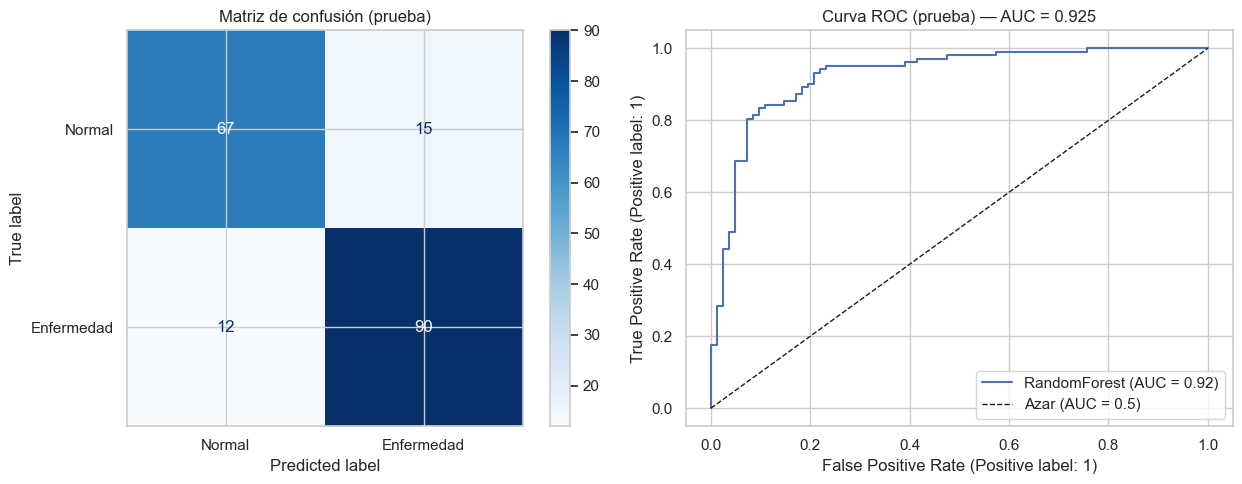

VP=90  FN=12  FP=15  VN=67
Sensibilidad = 0.882 | Especificidad = 0.817


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test, display_labels=["Normal", "Enfermedad"], cmap="Blues", ax=axes[0])
axes[0].set_title("Matriz de confusión (prueba)")

RocCurveDisplay.from_predictions(y_test, y_proba_test, name=MODEL_NAME, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0.5)")
axes[1].set_title(f"Curva ROC (prueba) — AUC = {roc_auc_score(y_test, y_proba_test):.3f}")
axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()
print(f"VP={tp}  FN={fn}  FP={fp}  VN={tn}")
print(f"Sensibilidad = {tp/(tp+fn):.3f} | Especificidad = {tn/(tn+fp):.3f}")

En un tamizaje clínico un **falso negativo** (paciente enfermo clasificado como sano) es más costoso que un falso positivo, que solo implica exámenes adicionales. Por eso se revisa cómo cambian sensibilidad y especificidad al mover el umbral de decisión. El umbral se analiza aquí solo de forma descriptiva; elegirlo con el conjunto de prueba sería otra forma de fuga, por lo que la API mantiene 0.5 por defecto.

In [10]:
umbrales = [0.3, 0.4, 0.5, 0.6, 0.7]
filas = []
for t in umbrales:
    p = (y_proba_test >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, p).ravel()
    filas.append({"umbral": t, "sensibilidad": tp_ / (tp_ + fn_), "especificidad": tn_ / (tn_ + fp_),
                  "accuracy": accuracy_score(y_test, p), "falsos negativos": fn_})
pd.DataFrame(filas).set_index("umbral").style.format("{:.3f}", subset=["sensibilidad", "especificidad", "accuracy"]).format_index("{:.1f}") \
    .set_caption("Compromiso sensibilidad–especificidad según el umbral")

,sensibilidad,especificidad,accuracy,falsos negativos
umbral,,,,
0.3,0.951,0.659,0.821,5
0.4,0.951,0.744,0.859,5
0.5,0.882,0.817,0.853,12
0.6,0.833,0.902,0.864,17
0.7,0.696,0.927,0.799,31


## 4. Verificación empírica de la ausencia de sobreajuste

Se replican las cuatro pruebas de la sección 10.18 del curso.

### 4.1 Comparación directa entrenamiento vs prueba

In [11]:
acc_train, acc_test = accuracy_score(y_train, y_pred_train), accuracy_score(y_test, y_pred_test)
auc_train, auc_test = roc_auc_score(y_train, y_proba_train), roc_auc_score(y_test, y_proba_test)
print(f"Accuracy — train: {acc_train:.4f} | test: {acc_test:.4f} | diferencia: {acc_train - acc_test:.4f}")
print(f"AUC      — train: {auc_train:.4f} | test: {auc_test:.4f} | diferencia: {auc_train - auc_test:.4f}")
print("Conclusión:", "diferencia reducida (< 5 p.p.)" if acc_train - acc_test < 0.05
      else "diferencia considerable; revisar regularización")

Accuracy — train: 0.9060 | test: 0.8533 | diferencia: 0.0527
AUC      — train: 0.9730 | test: 0.9247 | diferencia: 0.0483
Conclusión: diferencia considerable; revisar regularización


### 4.2 Validación cruzada con puntajes de entrenamiento y validación

In [12]:
cv_scores = cross_validate(best_model, X_train, y_train, cv=make_cv(5),
                           scoring=["accuracy", "roc_auc"], return_train_score=True, n_jobs=-1)
tabla_cv = pd.DataFrame({
    "Accuracy train": cv_scores["train_accuracy"], "Accuracy val": cv_scores["test_accuracy"],
    "AUC train": cv_scores["train_roc_auc"], "AUC val": cv_scores["test_roc_auc"],
}, index=[f"Pliegue {i}" for i in range(1, 6)])
tabla_cv.loc["Media"] = tabla_cv.mean()
tabla_cv.loc["Desv. estándar"] = tabla_cv.iloc[:5].std()
display(tabla_cv.style.format("{:.4f}").set_caption("Validación cruzada estratificada (5 pliegues)"))
print(f"Brecha media de accuracy train–val: {tabla_cv.loc['Media','Accuracy train'] - tabla_cv.loc['Media','Accuracy val']:.4f}")

,Accuracy train,Accuracy val,AUC train,AUC val
Pliegue 1,0.9199,0.8503,0.9743,0.9323
Pliegue 2,0.9080,0.7755,0.9764,0.8814
Pliegue 3,0.8927,0.8571,0.9709,0.9428
Pliegue 4,0.8927,0.9048,0.9699,0.9579
Pliegue 5,0.9082,0.8767,0.9731,0.9438
Media,0.9043,0.8529,0.9729,0.9316
Desv. estándar,0.0117,0.0481,0.0026,0.0295


Brecha media de accuracy train–val: 0.0514


### 4.3 Curva de aprendizaje

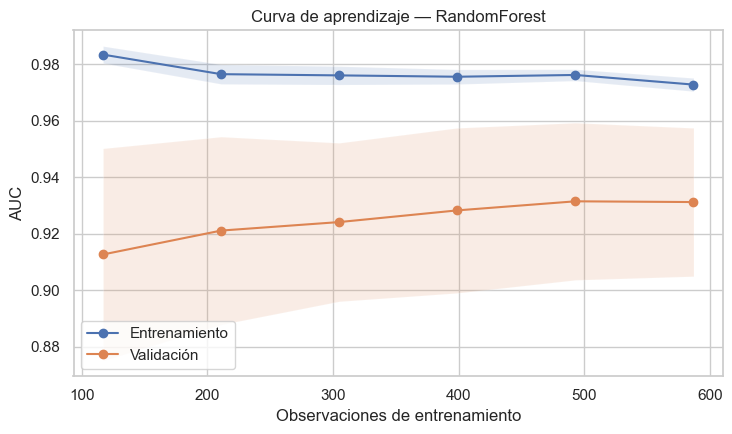

,n,AUC train,AUC val,brecha
0,117,0.9835,0.9127,0.0708
1,211,0.9766,0.9212,0.0554
2,305,0.9761,0.9242,0.0519
3,399,0.9757,0.9283,0.0473
4,493,0.9763,0.9315,0.0447
5,587,0.9729,0.9313,0.0416


In [13]:
sizes, tr_scores, val_scores = learning_curve(
    best_model, X_train, y_train, cv=make_cv(5), train_sizes=np.linspace(0.2, 1.0, 6),
    scoring="roc_auc", n_jobs=-1)
tr_m, val_m = tr_scores.mean(axis=1), val_scores.mean(axis=1)

plt.figure(figsize=(7.5, 4.5))
plt.plot(sizes, tr_m, "o-", label="Entrenamiento")
plt.fill_between(sizes, tr_m - tr_scores.std(axis=1), tr_m + tr_scores.std(axis=1), alpha=0.15)
plt.plot(sizes, val_m, "o-", label="Validación")
plt.fill_between(sizes, val_m - val_scores.std(axis=1), val_m + val_scores.std(axis=1), alpha=0.15)
plt.xlabel("Observaciones de entrenamiento"); plt.ylabel("AUC")
plt.title(f"Curva de aprendizaje — {MODEL_NAME}"); plt.legend(); plt.tight_layout(); plt.show()

pd.DataFrame({"n": sizes, "AUC train": tr_m, "AUC val": val_m, "brecha": tr_m - val_m}).round(4)

### 4.4 Prueba de permutación de la variable respuesta

AUC con la respuesta original:       0.9286
AUC medio con respuestas permutadas: 0.5071 (d.e. 0.0287)
Valor p empírico: 0.0323


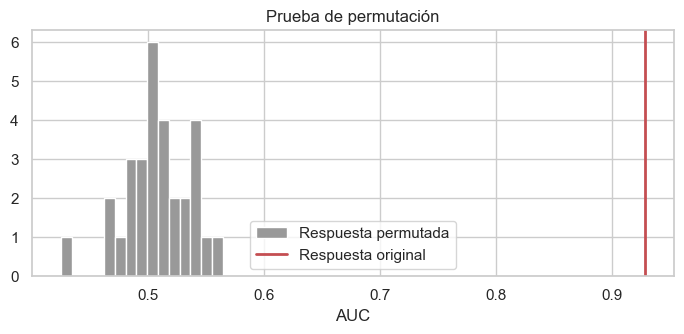

In [14]:
score_real, perm_scores, p_valor = permutation_test_score(
    best_model, X_train, y_train, cv=make_cv(3), n_permutations=30,
    scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=-1)
print(f"AUC con la respuesta original:       {score_real:.4f}")
print(f"AUC medio con respuestas permutadas: {perm_scores.mean():.4f} (d.e. {perm_scores.std():.4f})")
print(f"Valor p empírico: {p_valor:.4f}")

plt.figure(figsize=(7, 3.5))
plt.hist(perm_scores, bins=15, color="#999999", label="Respuesta permutada")
plt.axvline(score_real, color="#C44E52", lw=2, label="Respuesta original")
plt.xlabel("AUC"); plt.title("Prueba de permutación"); plt.legend(); plt.tight_layout(); plt.show()

**Lectura conjunta.**

- **Prueba 1 y 2:** la brecha de *accuracy* entre entrenamiento y prueba/validación es de ~5 puntos porcentuales, justo en el límite orientativo de 5 p.p. del curso. Es la brecha típica de un bosque aleatorio, que tiende a ajustar muy bien el entrenamiento; la búsqueda ya eligió la configuración más regularizada que maximiza el AUC (`max_depth=8`, `min_samples_leaf=5`). La dispersión entre pliegues de validación (d.e. ≈ 0.03 en AUC) es mayor que la brecha entre modelos del ranking, lo que refuerza que los cuatro modelos son prácticamente equivalentes.
- **Prueba 3:** la brecha de AUC entre entrenamiento y validación **disminuye** de forma monótona al aumentar el tamaño muestral (de ~0.07 a ~0.04) mientras la validación sube: es el patrón de un modelo que se beneficia de más datos, no el de un sobreajuste severo.
- **Prueba 4:** con la respuesta permutada el AUC cae a ≈ 0.5, frente a ≈ 0.93 con la original. Con 30 permutaciones el valor p mínimo alcanzable es 1/31 ≈ 0.032, que es justo el obtenido: ninguna permutación igualó al modelo real. Para un valor p más fino basta aumentar `n_permutations` (a costa de tiempo de cómputo).

Si se quisiera reducir la brecha, alternativas razonables serían `min_samples_leaf` mayores o un modelo más simple como la regresión logística, cuyo AUC de validación es estadísticamente equivalente.

## 5. Importancia de las variables (permutación sobre el conjunto de prueba)

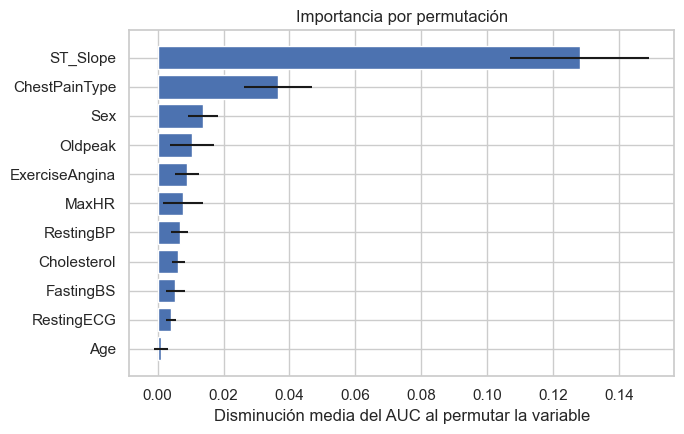

In [15]:
imp = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                             n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp_df = pd.DataFrame({"variable": X_test.columns, "importancia": imp.importances_mean,
                       "d.e.": imp.importances_std}).sort_values("importancia")
plt.figure(figsize=(7, 4.5))
plt.barh(imp_df["variable"], imp_df["importancia"], xerr=imp_df["d.e."], color="#4C72B0")
plt.xlabel("Disminución media del AUC al permutar la variable")
plt.title("Importancia por permutación"); plt.tight_layout(); plt.show()

La importancia por permutación se calcula sobre las variables originales (antes del one-hot), por lo que es directamente interpretable. Coincide con el EDA: `ST_Slope`, `ChestPainType` y las variables de la prueba de esfuerzo concentran la señal.

## 6. Exportación del modelo

Se guarda el **pipeline completo** (`grid.best_estimator_`), no solo el clasificador: así la API aplica exactamente la misma imputación, codificación y, cuando corresponde, escalado aprendidos en entrenamiento.

In [16]:
app_dir = ROOT / "app"
app_dir.mkdir(exist_ok=True)
joblib.dump(grid.best_estimator_, app_dir / "model.joblib")  # lo carga la API (app/model.joblib)
joblib.dump(grid.best_estimator_, ROOT / "model.joblib")     # copia en la raíz (estructura Etapa 0)

resumen = {
    "modelo": MODEL_NAME,
    "mejores_parametros": {k.replace("clf__", ""): v for k, v in grid.best_params_.items()},
    "auc_cv": round(float(grid.best_score_), 4),
    "auc_test": round(float(auc_test), 4),
    "accuracy_test": round(float(acc_test), 4),
    "sklearn_version": sklearn.__version__,
}
print(json.dumps(resumen, indent=2, ensure_ascii=False))

{
  "modelo": "RandomForest",
  "mejores_parametros": {
    "max_depth": 8,
    "min_samples_leaf": 5,
    "n_estimators": 200
  },
  "auc_cv": 0.9316,
  "auc_test": 0.9247,
  "accuracy_test": 0.8533,
  "sklearn_version": "1.3.0"
}


In [17]:
# Verificación: el modelo exportado se carga y predice igual que en memoria
modelo_cargado = joblib.load(app_dir / "model.joblib")
assert np.allclose(modelo_cargado.predict_proba(X_test)[:, 1], y_proba_test)

paciente = pd.DataFrame([{"Age": 58, "Sex": "M", "ChestPainType": "ASY", "RestingBP": 140,
                          "Cholesterol": 0, "FastingBS": 1, "RestingECG": "Normal", "MaxHR": 110,
                          "ExerciseAngina": "Y", "Oldpeak": 2.0, "ST_Slope": "Flat"}])
print("Probabilidad de enfermedad del paciente de ejemplo:",
      round(float(modelo_cargado.predict_proba(paciente)[0, 1]), 3))

Probabilidad de enfermedad del paciente de ejemplo: 0.976


## 7. Etapa 6 · Monitoreo de deriva de datos con Evidently

Se compara la distribución de las variables de entrenamiento (referencia) con la de los datos nuevos (aquí, el conjunto de prueba), con el código del enunciado. El reporte se guarda en `drift_report.html`, en la raíz del proyecto.

In [18]:
import os
from evidently.report import Report
from evidently.metric_preset import DataDriftPreset

os.chdir(ROOT)  # drift_report.html queda en la raíz del proyecto

report = Report(metrics=[DataDriftPreset()])
report.run(reference_data=X_train, current_data=X_test)
report.save_html("drift_report.html")

res = report.as_dict()["metrics"][0]["result"]
print(f"Columnas con deriva: {res['number_of_drifted_columns']} de {res['number_of_columns']}")
print("¿Deriva del dataset?:", "Sí" if res["dataset_drift"] else "No")

Columnas con deriva: 1 de 11
¿Deriva del dataset?: No


Como el conjunto de prueba sale de la misma población que el entrenamiento, se espera poca o ninguna deriva. Para comprobar que el monitoreo sí la detecta, se simula una población distinta: pacientes 10 años mayores, más dolor torácico asintomático, menor frecuencia cardíaca máxima y colesterol 15 % más alto.

In [19]:
rng = np.random.default_rng(0)
X_drift = X_test.copy()
X_drift["Age"] = (X_drift["Age"] + rng.normal(10, 3, len(X_drift))).round().clip(18, 100)
X_drift["Cholesterol"] = np.where(X_drift["Cholesterol"] > 0, X_drift["Cholesterol"] * 1.15, 0)
X_drift["MaxHR"] = X_drift["MaxHR"] - rng.normal(15, 5, len(X_drift))
X_drift.loc[rng.random(len(X_drift)) < 0.4, "ChestPainType"] = "ASY"

report_sim = Report(metrics=[DataDriftPreset()])
report_sim.run(reference_data=X_train, current_data=X_drift)

res = report_sim.as_dict()["metrics"][0]["result"]
print(f"Columnas con deriva: {res['number_of_drifted_columns']} de {res['number_of_columns']}")
print("¿Deriva del dataset?:", "Sí" if res["dataset_drift"] else "No",
      "(umbral por defecto: 50 % de las columnas)")

Columnas con deriva: 4 de 11
¿Deriva del dataset?: No (umbral por defecto: 50 % de las columnas)


## 8. Conclusiones

- La partición se hizo antes de cualquier transformación y todo el preprocesamiento quedó dentro del pipeline, de modo que la estimación del desempeño es honesta.
- El modelo final generaliza de forma consistente: las métricas de prueba están en línea con las de validación cruzada y las pruebas de sobreajuste no muestran señales graves.
- El artefacto `app/model.joblib` contiene el pipeline completo y es el que sirve la API de la Etapa 3.
- El reporte de Evidently (`drift_report.html`) no muestra deriva entre entrenamiento y prueba, y sí detecta la deriva simulada en las variables alteradas.